# Machine Learning-Based Mental Health Assessment & Recommendation System
**Educational project - not a medical or diagnostic tool.**

This notebook upgrades the original "predict a score" project into a complete system:

| Step | What you get |
|---|---|
| 1 | A cleaned, honest, well-tested ML model that predicts a 0-10 wellbeing score |
| 2 | Cross-validation, a baseline, and a final untouched test set |
| 3 | **Explainable AI (SHAP):** which habits pushed the score up or down |
| 4 | **Personalised written advice** (rule-based, easy to defend) |
| 5 | **What-if tests:** "what if I sleep 30 minutes more?" |
| 6 | A **4-week improvement plan** and a Mon-Sun schedule |
| 7 | **YouTube + Coursera/edX recommendations** from a curated list |
| 8 | A saved model (`Mental_Health_Model.pkl`) used by the Streamlit dashboard (`app.py`) |

**How to run:** click *Run all*. It takes a few minutes. It creates `Mental_Health_Model.pkl`, `mh_engine.py`, `resources.csv` and `requirements.txt` next to the notebook.

**Credit:** the starting point (load, clean, `Pipeline`, Random Forest) follows the public project `github.com/tanishq-latent/Mental-Health-Score`. Cite it in your report. Everything from the "feature audit" onwards - the explainability, recommendations, plan and dashboard - is the new work you present as yours (and must be able to explain).

## 1. Setup
`shap` is the Explainable-AI library. If it is missing, the next cell installs it.

In [1]:
import sys, subprocess, importlib.util, warnings
if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Project settings (shared with the dashboard)
These constants say which columns the model uses, the valid ranges, and how scores are turned into bands.
They live in `mh_engine.py`, so the notebook and the dashboard always agree.

**Design decision (defend this in your viva):** the model uses only **7 inputs a student can actually describe and change** - 5 habit numbers plus academic level and purpose of use. Section 6 shows the evidence for leaving out country, gender, age, platform and stress level.

In [2]:
NUMERIC_FEATURES = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
]
CATEGORICAL_FEATURES = ["Academic_Level", "Purpose_Of_Use"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "Mental_Health_Score"

CHOICES = {
    "Academic_Level": ["High School", "Undergraduate", "Graduate"],
    "Purpose_Of_Use": ["Education", "Entertainment", "Networking", "News"],
}
# Allowed input ranges = (a little wider than) the range seen in the training data
VALID_RANGES = {
    "Avg_Daily_Usage_Hours": (1.0, 9.0),
    "Daily_Unlocks": (60, 280),
    "Study_Hours": (0.3, 8.5),
    "Physical_Activity_Hours": (0.0, 4.2),
    "Sleep_Hours_Per_Night": (3.5, 10.0),
}
FRIENDLY = {
    "Avg_Daily_Usage_Hours": "Daily social-media time",
    "Daily_Unlocks": "Phone checks per day",
    "Study_Hours": "Study time",
    "Physical_Activity_Hours": "Physical activity",
    "Sleep_Hours_Per_Night": "Sleep",
    "Academic_Level": "Academic level",
    "Purpose_Of_Use": "Main purpose of social media",
}
UNITS = {
    "Avg_Daily_Usage_Hours": "h/day", "Daily_Unlocks": "times/day",
    "Study_Hours": "h/day", "Physical_Activity_Hours": "h/day",
    "Sleep_Hours_Per_Night": "h/night",
}
# Score bands (design choice: cut-offs at 5 and 7 give roughly 17% / 51% / 32% of students)
BAND_EDGES = (5.0, 7.0)
BAND_NAMES = ("Needs attention", "Moderate", "Good")

DISCLAIMER = (
    "Educational project - not a medical or psychological diagnosis. The score comes from a "
    "machine-learning model trained on a public student-survey dataset and has not been "
    "clinically validated. Your answers are used only to compute this result and are not saved."
)
SUPPORT_NOTE = (
    "If you have felt low for a long time, or have thoughts of harming yourself, please talk to "
    "someone you trust, a doctor, or a counsellor. In Pakistan you can call the Umang helpline on "
    "0311-7786264 (listed as 24/7 - check umang.com.pk for current details). If you are in "
    "immediate danger, contact your local emergency services."
)

**Score bands and input checking.** Never trust inputs: `validate_inputs` rejects missing values and bad categories and gently adjusts out-of-range numbers with a warning. `score_to_band` turns a number into a band name (the cut-offs 5 and 7 are a design choice).

In [3]:
def score_to_band(score):
    """Turn a 0-10 score into a band name."""
    if score < BAND_EDGES[0]:
        return BAND_NAMES[0]
    if score < BAND_EDGES[1]:
        return BAND_NAMES[1]
    return BAND_NAMES[2]


def validate_inputs(raw):
    """Check the user's inputs. Returns (clean_row, warnings). Raises ValueError if unusable."""
    row, warnings = {}, []
    for f in NUMERIC_FEATURES:
        if f not in raw or raw[f] is None or pd.isna(raw[f]):
            raise ValueError(f"Missing value for {FRIENDLY[f]}")
        value = float(raw[f])
        lo, hi = VALID_RANGES[f]
        if value < lo or value > hi:
            warnings.append(f"{FRIENDLY[f]} = {value:g} is outside the range the model "
                            f"was trained on ({lo:g}-{hi:g}); it was adjusted to fit.")
            value = min(max(value, lo), hi)
        row[f] = value
    for f in CATEGORICAL_FEATURES:
        if raw.get(f) not in CHOICES[f]:
            raise ValueError(f"{FRIENDLY[f]} must be one of {CHOICES[f]}")
        row[f] = raw[f]
    return row, warnings

## 3. Load the data
The cell looks for the CSV next to the notebook (or in Colab's `/content`). In Colab, if it is not found, it asks you to upload it.

In [4]:
from pathlib import Path
CANDIDATES = ["Student_Social_Media_And_Mental_Health_Impact.csv",
              "Student Social Media And Mental Health Impact.csv",
              "/content/Student_Social_Media_And_Mental_Health_Impact.csv"]
DATA_PATH = next((p for p in CANDIDATES if Path(p).exists()), None)
if DATA_PATH is None:
    try:
        from google.colab import files          # only works inside Google Colab
        DATA_PATH = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError("Put Student_Social_Media_And_Mental_Health_Impact.csv next to this notebook.")
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, df.shape)
df.head()

Loaded: Student_Social_Media_And_Mental_Health_Impact.csv (5000, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Pakistan,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Pakistan,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Pakistan,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Pakistan,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 4. Data audit and cleaning
We always *check* before we clean. The original notebook text said "zero duplicates", but its own output showed 2 - so we print the real numbers.

In [5]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Negative physical-activity values:", int((df["Physical_Activity_Hours"] < 0).sum()), "(impossible)")
display(df.describe().T[["min", "mean", "max"]].round(2))

Missing values: 0
Duplicate rows: 2
Negative physical-activity values: 10 (impossible)


,min,mean,max
Age,18.0,20.82,24.0
Avg_Daily_Usage_Hours,1.0,5.08,8.8
Daily_Unlocks,62.0,171.45,273.0
Study_Hours,0.3,3.01,8.3
Physical_Activity_Hours,-0.4,1.75,4.1
Sleep_Hours_Per_Night,3.6,6.63,9.9
Mental_Health_Score,3.6,6.23,9.4


In [6]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)                       # remove repeated rows
df["Physical_Activity_Hours"] = df["Physical_Activity_Hours"].clip(lower=0)   # negative hours are impossible
print(f"Rows: {n_before} -> {len(df)} after removing duplicates; negative activity values set to 0.")

Rows: 5000 -> 4998 after removing duplicates; negative activity values set to 0.


## 5. Exploratory data analysis (EDA)
Four plots, each answering one question: how is the score spread, what moves with it, does stress track it, does sleep track it.

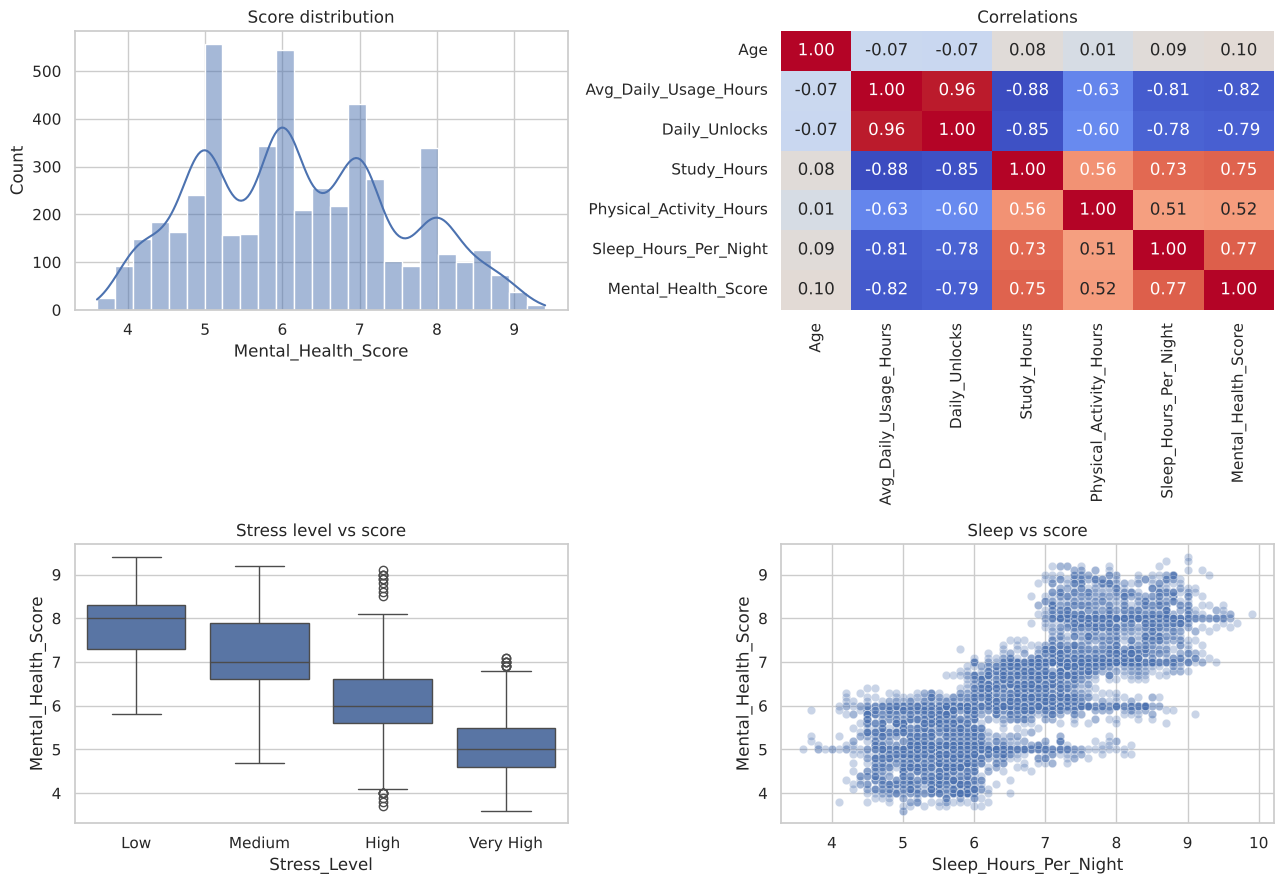

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(df[TARGET], kde=True, ax=ax[0, 0]); ax[0, 0].set_title("Score distribution")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[0, 1], cbar=False)
ax[0, 1].set_title("Correlations")
sns.boxplot(x="Stress_Level", y=TARGET, data=df, order=["Low", "Medium", "High", "Very High"], ax=ax[1, 0])
ax[1, 0].set_title("Stress level vs score")
sns.scatterplot(x="Sleep_Hours_Per_Night", y=TARGET, data=df, alpha=0.3, ax=ax[1, 1]); ax[1, 1].set_title("Sleep vs score")
plt.tight_layout(); plt.show()

**Reading the plots:** the score falls with more screen time and phone checks and rises with sleep, study time and activity. Stress level also tracks the score strongly - but see section 7 for why that is not as useful as it looks.

## 6. Train / test split
We split **before** doing any experiments or fitting. The test set (20%) stays locked away until the very end, so its score is an honest estimate for new students. (The original text said 80/20 but the code used 70/30; this version really uses 80/20.)

In [8]:
df["Grouped_Country"] = df["Country"].where(df["Country"].isin(df["Country"].value_counts().index[:10]), "Other")
y = df[TARGET]
X_train_all, X_test_all, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=RANDOM_STATE)
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3998, 7)  Test: (1000, 7)


## 7. Feature audit: which inputs should the model use?
**Preprocessing as a pipeline.** Numbers are imputed (median) and scaled, categories are imputed (most frequent) and one-hot encoded. Putting this inside a `Pipeline` means it is fitted on training data only - this prevents *data leakage*.

Then we run a **5-fold cross-validation experiment on the training set** with a Random Forest, adding one group of inputs at a time.

In [9]:
def make_preprocessor(num, cat=(), ordinal=()):
    parts = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), list(num))]
    if cat:
        parts.append(("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), list(cat)))
    if ordinal:
        parts.append(("ord", OrdinalEncoder(categories=[["Low", "Medium", "High", "Very High"]]), list(ordinal)))
    return ColumnTransformer(parts)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def cv_rf(label, num, cat=(), ordinal=()):
    pipe = Pipeline([("prep", make_preprocessor(num, cat, ordinal)),
                     ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1))])
    cols = list(num) + list(cat) + list(ordinal)
    r = cross_validate(pipe, X_train_all[cols], y_train, cv=kf, scoring=("r2", "neg_mean_absolute_error"))
    return {"Input set": label, "# inputs": len(cols), "CV R2": r["test_r2"].mean(), "CV MAE": -r["test_neg_mean_absolute_error"].mean()}

audit = pd.DataFrame([
    cv_rf("A. Habits only", NUMERIC_FEATURES),
    cv_rf("B. A + academic level + purpose  (FINAL)", NUMERIC_FEATURES, CATEGORICAL_FEATURES),
    cv_rf("C. B + Stress_Level", NUMERIC_FEATURES, CATEGORICAL_FEATURES, ["Stress_Level"]),
    cv_rf("D. B + country, gender, age, platform", NUMERIC_FEATURES + ["Age"],
          CATEGORICAL_FEATURES + ["Gender", "Grouped_Country", "Most_Used_Platform"]),
]).round(3)
audit

,Input set,# inputs,CV R2,CV MAE
0,A. Habits only,5,0.782,0.458
1,B. A + academic level + purpose (FINAL),7,0.808,0.428
2,C. B + Stress_Level,8,0.809,0.426
3,"D. B + country, gender, age, platform",11,0.841,0.380


**What the audit shows (and why we chose set B):**

* **Stress level adds almost nothing** (B vs C). It is mostly a summary of the same habits, and asking a student "how stressed are you?" to predict a wellbeing score is nearly circular. Leaving it out also keeps the tool honest and shorter to fill in.
* **Country, gender, age and platform raise accuracy (B vs D)** - mainly country (the score differs by country in this dataset, which suggests a country-specific offset, a typical sign of a simulated dataset). But a student cannot change their country or age, collecting them is a privacy cost, and advice should never depend on who you are. So the dashboard model excludes them: **a small accuracy loss in exchange for fairness, privacy and actionable advice.**
* The dataset has no depression or diagnosis column, so we predict a **wellbeing score** and group it into bands. We make **no diagnostic claims.**

## 8. Compare models fairly
Same preprocessing, same 5 folds, training data only. A **baseline** that always predicts the average tells us what "no skill" looks like - any real model must beat it clearly.

In [10]:
def make_pipe(model):
    return Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)), ("model", model)])

candidates = {
    "Baseline (always the average)": make_pipe(DummyRegressor()),
    "Ridge (linear)": make_pipe(Ridge()),
    "Random Forest": make_pipe(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    "Hist Gradient Boosting": make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}
def cv_row(name, pipe):
    r = cross_validate(pipe, X_train, y_train, cv=kf, return_train_score=True,
                       scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    return {"Model": name, "Train R2": r["train_r2"].mean(), "CV R2": r["test_r2"].mean(), "CV R2 std": r["test_r2"].std(),
            "CV MAE": -r["test_neg_mean_absolute_error"].mean(), "CV RMSE": -r["test_neg_root_mean_squared_error"].mean()}

cv_table = pd.DataFrame([cv_row(n, p) for n, p in candidates.items()]).set_index("Model")
cv_table.round(3)

,Train R2,CV R2,CV R2 std,CV MAE,CV RMSE
Model,,,,,
Baseline (always the average),0.000,-0.001,0.002,1.051,1.263
Ridge (linear),0.706,0.703,0.006,0.546,0.688
Random Forest,0.902,0.808,0.009,0.427,0.552
Gradient Boosting,0.802,0.773,0.012,0.473,0.601
Hist Gradient Boosting,0.892,0.806,0.007,0.433,0.556


## 9. Tune the Random Forest, then pick the winner by cross-validation
`RandomizedSearchCV` tries a sample of settings. The original search capped `max_depth` at 15 and ended up *worse* than the default model; here we also allow unlimited depth and `max_features`. The tuned model is then scored with the **same 5 folds** as the others so the comparison is fair.

In [11]:
param_dist = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 12, 20],
    "model__min_samples_leaf": [2, 3, 5, 8],
    "model__max_features": [1.0, 0.6],
}
search = RandomizedSearchCV(make_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)), param_dist,
                            n_iter=6, cv=3, scoring="r2", random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)
candidates["Random Forest (tuned)"] = clone(search.best_estimator_)
tuned_row = cv_row("Random Forest (tuned)", candidates["Random Forest (tuned)"])
cv_table.loc["Random Forest (tuned)"] = pd.Series({k: v for k, v in tuned_row.items() if k != "Model"})
display(cv_table.round(3))

# Only tree models can be explained with TreeSHAP, so we pick the best of those for deployment.
deployable = [n for n in candidates if "Baseline" not in n and "Ridge" not in n]
best_name = cv_table.loc[deployable, "CV R2"].idxmax()
final_pipe = clone(candidates[best_name])
print("\nChosen for deployment:", best_name)

Best settings: {'model__n_estimators': 150, 'model__min_samples_leaf': 2, 'model__max_features': 0.6, 'model__max_depth': 20}


,Train R2,CV R2,CV R2 std,CV MAE,CV RMSE
Model,,,,,
Baseline (always the average),0.000,-0.001,0.002,1.051,1.263
Ridge (linear),0.706,0.703,0.006,0.546,0.688
Random Forest,0.902,0.808,0.009,0.427,0.552
Gradient Boosting,0.802,0.773,0.012,0.473,0.601
Hist Gradient Boosting,0.892,0.806,0.007,0.433,0.556
Random Forest (tuned),0.952,0.828,0.007,0.403,0.524



Chosen for deployment: Random Forest (tuned)


## 10. Final test-set evaluation (the honest number)
The locked test set is used **once**. We also compare train vs test to check for over-fitting (the original default forest scored 0.98 on training data but 0.88 on test data - a big gap).

{'test_r2': 0.85, 'test_mae': 0.398, 'test_rmse': 0.518, 'train_r2': 0.955, 'baseline_mae': 1.128}

On average the prediction is 0.40 points off (the do-nothing baseline is 1.13).


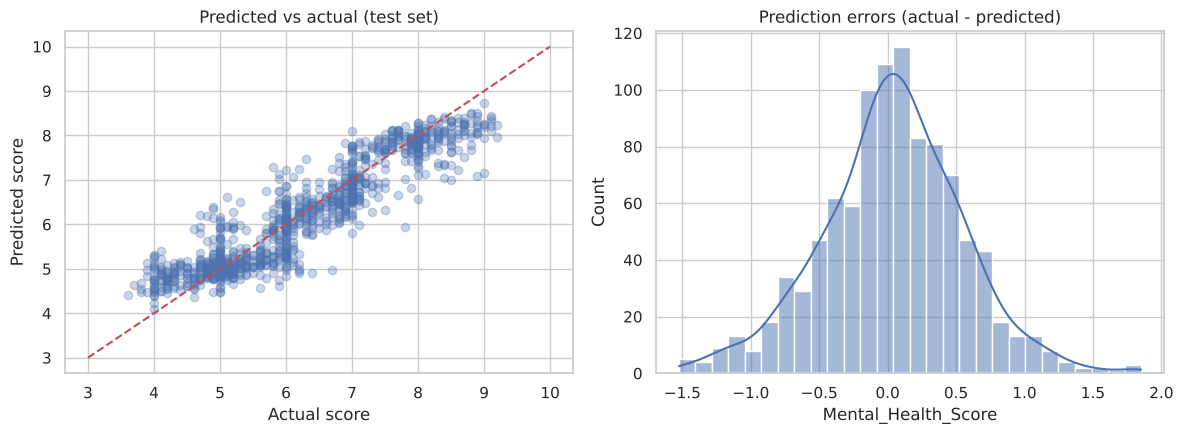

In [12]:
final_pipe.fit(X_train, y_train)
pred_test, pred_train = final_pipe.predict(X_test), final_pipe.predict(X_train)
metrics = {
    "test_r2": r2_score(y_test, pred_test),
    "test_mae": mean_absolute_error(y_test, pred_test),
    "test_rmse": float(np.sqrt(mean_squared_error(y_test, pred_test))),
    "train_r2": r2_score(y_train, pred_train),
    "baseline_mae": mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())),
}
print({k: round(v, 3) for k, v in metrics.items()})
print(f"\nOn average the prediction is {metrics['test_mae']:.2f} points off (the do-nothing baseline is {metrics['baseline_mae']:.2f}).")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred_test, alpha=0.3); ax[0].plot([3, 10], [3, 10], "r--")
ax[0].set_xlabel("Actual score"); ax[0].set_ylabel("Predicted score"); ax[0].set_title("Predicted vs actual (test set)")
sns.histplot(y_test - pred_test, kde=True, ax=ax[1]); ax[1].set_title("Prediction errors (actual - predicted)")
plt.tight_layout(); plt.show()

**Score bands.** The dashboard shows a band as well as a number. How often does the model put a student in the right band?

In [13]:
true_band = y_test.apply(score_to_band); pred_band = pd.Series(pred_test, index=y_test.index).apply(score_to_band)
print(f"Band accuracy on the test set: {(true_band == pred_band).mean():.1%}")
display(pd.crosstab(true_band, pred_band, rownames=["Actual band"], colnames=["Predicted band"]).reindex(
    index=list(BAND_NAMES), columns=list(BAND_NAMES), fill_value=0))

Band accuracy on the test set: 78.8%


Predicted band,Needs attention,Moderate,Good
Actual band,,,
Needs attention,113,64,0
Moderate,65,407,17
Good,0,66,268


## 11. Prediction range and saving the model
A single number looks more certain than it is. We measure how wrong the model usually is using **out-of-fold predictions on the training set**, and keep the 10th and 90th percentile of the errors. The dashboard shows "score +/- typical error". We then check on the test set that the range really covers about 80% of students.

We save **one file** containing the whole pipeline (preprocessing + model) plus the settings the dashboard needs. The original notebook saved a model that expected a column called `Grouped_Countries` while the notebook created `Grouped_country`; saving one pipeline that only needs the 7 clean inputs avoids that kind of mismatch.

In [14]:
oof = cross_val_predict(clone(final_pipe), X_train, y_train, cv=kf)
q10, q90 = np.quantile(y_train - oof, [0.10, 0.90])
coverage = ((y_test >= pred_test + q10) & (y_test <= pred_test + q90)).mean()
print(f"80% range = prediction {q10:+.2f} to {q90:+.2f}; it covers {coverage:.1%} of test students.")

artifact = {
    "pipeline": final_pipe, "features": FEATURES, "model_name": best_name,
    "band_edges": BAND_EDGES, "band_names": BAND_NAMES,
    "residual_q10": float(q10), "residual_q90": float(q90),
    "metrics": {k: float(v) for k, v in metrics.items()},
    "sklearn_version": sklearn.__version__, "trained_rows": int(len(X_train)),
    "note": "Educational project - not a diagnostic tool.",
}
joblib.dump(artifact, "Mental_Health_Model.pkl", compress=3)
print("Saved Mental_Health_Model.pkl ->", round(Path("Mental_Health_Model.pkl").stat().st_size / 1e6, 1), "MB")

80% range = prediction -0.67 to +0.65; it covers 80.1% of test students.


Saved Mental_Health_Model.pkl -> 5.6 MB


## 12. Explainable AI with SHAP
**Idea in one line:** SHAP shares the prediction fairly among the inputs. For each student it says "your sleep lowered your score by 0.4 points, your phone checks lowered it by 0.2..." compared with the *average* student.

First the **global** picture (which inputs matter most across many students), then the **local** picture (one student). Contributions of one-hot columns are added back together so each original input gets one number.

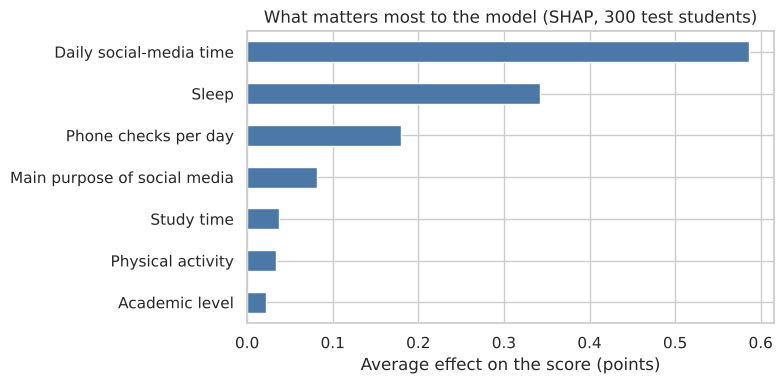

In [15]:
import shap
prep, model = final_pipe.named_steps["prep"], final_pipe.named_steps["model"]
sample = X_test.sample(300, random_state=RANDOM_STATE)
Xt = prep.transform(sample)
sv = np.asarray(shap.TreeExplainer(model).shap_values(Xt))
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

def original_feature(n):
    return next(f for f in FEATURES if n == f or n.startswith(f + "_"))
sv_df = pd.DataFrame(sv, columns=names)
by_feature = pd.DataFrame({f: sv_df[[c for c in names if original_feature(c) == f]].sum(axis=1) for f in FEATURES})
global_importance = by_feature.abs().mean().sort_values()          # mean |SHAP| per original feature
global_importance.rename(index=FRIENDLY).plot.barh(figsize=(8, 4), color="#4C78A8")
plt.xlabel("Average effect on the score (points)"); plt.title("What matters most to the model (SHAP, 300 test students)")
plt.tight_layout(); plt.show()

**How to explain this in the viva:** "The bar length is the average number of score points an input moves a prediction up or down. Sleep, screen time and phone checks matter most. This is what the model *learned from this dataset* - it shows association, not proof of cause and effect."

### 13.1 Prediction and the local SHAP explanation
`explain_prediction` returns, for one student, how many points each input added or removed. A useful check: *base value + all contributions = the prediction* (SHAP is "additive"). We test that later.

In [16]:
def predict_score(artifact, row):
    """Predicted wellbeing score (0-10) for one student."""
    X = pd.DataFrame([row])[FEATURES]
    return float(np.clip(artifact["pipeline"].predict(X)[0], 0, 10))


_EXPLAINERS = {}


def explain_prediction(artifact, row):
    """
    SHAP explanation for one student.
    SHAP gives every column of the encoded data a contribution; we add the one-hot columns back
    together so each ORIGINAL feature gets one number: how many score points it added (+) or
    removed (-) compared with the average student.
    Returns (table, base_value).
    """
    import shap  # imported here so the rest of the module works without SHAP installed
    pipe = artifact["pipeline"]
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    if id(model) not in _EXPLAINERS:
        _EXPLAINERS[id(model)] = shap.TreeExplainer(model)
    explainer = _EXPLAINERS[id(model)]

    Xt = prep.transform(pd.DataFrame([row])[FEATURES])
    values = np.asarray(explainer.shap_values(Xt))[0]
    base = float(np.ravel(explainer.expected_value)[0])

    contrib = {f: 0.0 for f in FEATURES}
    for name, v in zip(prep.get_feature_names_out(), values):
        short = name.split("__", 1)[1]
        for f in FEATURES:
            if short == f or short.startswith(f + "_"):
                contrib[f] += float(v)
                break
    table = pd.DataFrame({
        "feature": FEATURES,
        "label": [FRIENDLY[f] for f in FEATURES],
        "value": [row[f] for f in FEATURES],
        "contribution": [contrib[f] for f in FEATURES],
    }).sort_values("contribution").reset_index(drop=True)
    return table, base


def describe_driver(r):
    """One plain-English sentence for one row of the SHAP table."""
    f, c = r["feature"], r["contribution"]
    value = f"{r['value']:g} {UNITS[f]}" if f in UNITS else str(r["value"])
    if abs(c) < 0.05:
        return f"{r['label']} ({value}) had almost no effect."
    direction = "raised" if c > 0 else "lowered"
    return f"{r['label']} ({value}) {direction} your score by about {abs(c):.2f} points compared with the average student."

### 13.2 Written advice (rule-based on purpose)
Advice is written only for the habits chosen in the next step (habits that lower this student's score or have a clear estimated gain), most important first. We use plain rules instead of a generative model so every sentence can be traced and defended, and nothing medical is invented. General guidance quoted (7-9 hours of sleep, 150 minutes of activity a week) is widely used public-health guidance for adults.

In [17]:
def advice_for(feature, row):
    """Short, practical advice text for one habit. Written for a student audience."""
    v = row.get(feature)
    if feature == "Sleep_Hours_Per_Night":
        if v < 7:
            return (f"You sleep about {v:.1f} hours a night. Most adults feel best with 7-9 hours. Try going "
                    "to bed 15-20 minutes earlier every few days, keep the same wake-up time, and keep your "
                    "phone out of reach for the last 30 minutes before sleep.")
        return (f"Your sleep ({v:.1f} h) is in a healthy range. Protect it by keeping a regular bedtime - "
                "irregular timing can hurt as much as too few hours.")
    if feature == "Physical_Activity_Hours":
        return (f"You get about {v * 60:.0f} minutes of physical activity a day. Adults are generally advised to "
                "aim for at least 150 minutes of moderate activity a week (roughly 20-30 minutes a day). Start "
                "with a 15-minute walk after class or after a meal and add 5 minutes each week.")
    if feature == "Avg_Daily_Usage_Hours":
        return (f"You spend about {v:.1f} hours a day on social media. There is no magic number, but cutting "
                "back gradually (30-60 minutes) works better than quitting suddenly. Use app timers, and make "
                "the last hour before bed phone-free.")
    if feature == "Daily_Unlocks":
        return (f"You pick up your phone about {v:.0f} times a day. Turn off non-essential notifications, move "
                "distracting apps off your home screen, and check messages in batches (for example once an hour).")
    if feature == "Study_Hours":
        return (f"You study about {v:.1f} hours a day. In this dataset, students with a steady study routine "
                "scored higher. Try two or three focused 45-minute blocks with 10-minute breaks, at the same "
                "times each day. (Study time and screen time are linked in the data, so treat this as a pattern, "
                "not a rule.)")
    if feature == "Purpose_Of_Use":
        return ("Most of your social-media time is for entertainment. Moving part of it to learning or real "
                "connection (messaging a friend, a study group, a skill video) can make the time feel more worthwhile.")
    return ""

### 13.3 Choosing changes and estimating their effect
Two different questions, two different tools - an important point for your viva:

* **SHAP asks:** "compared with the *average student*, what is hurting *this* student?" (explanation)
* **What-if asks:** "if *this* student changed one habit, what would the model predict?" (simulation)

**Targets come from simple rules** (for example +1 hour of sleep over 4 weeks, never beyond 8 hours), so they are safe and easy to explain. A habit is chosen if SHAP says it lowers the score or the model estimates a clear gain. The model then estimates the effect of reaching **all** targets together, which is more stable than one habit at a time.

**Honesty about noise:** the model is typically 0.4 points off, and tree models respond in small jumps, so single-habit gains below about 0.1 points are noise and are not advertised. All estimates are patterns in the data, not guaranteed effects.

In [18]:
# Rule-based targets: (step, limit) = add/subtract 'step' over 4 weeks but never go past 'limit'
STEPS = {
    "Sleep_Hours_Per_Night": (+1.0, 8.0),
    "Physical_Activity_Hours": (+0.3, 2.0),
    "Avg_Daily_Usage_Hours": (-1.0, 2.5),
    "Daily_Unlocks": (-40, 100),
    "Study_Hours": (+0.5, 4.0),
}


def what_if(artifact, row, changes):
    """Predicted score if the habits in `changes` (dict feature -> new value) were different."""
    return predict_score(artifact, {**row, **changes})


def suggest_changes(artifact, row, drivers=None, min_gain=0.10):
    """
    Choose which habits to work on, and by how much.
      * the TARGET comes from a simple rule (STEPS) - easy to explain and safe;
      * a habit is chosen if it lowers this student's score (SHAP) or if the model estimates a clear gain;
      * the model's estimate is shown as 'gain' (a pattern in the data, not a guaranteed effect).
    Single-habit estimates from tree models are noisy (typical error is about 0.4 points), so small
    gains are kept but not advertised. Returns a list, most important first.
    """
    current = predict_score(artifact, row)
    hurt = {} if drivers is None else {f: -c for f, c in zip(drivers["feature"], drivers["contribution"])}
    out = []
    for f, (step, limit) in STEPS.items():
        cur = row[f]
        if (step > 0 and cur >= limit) or (step < 0 and cur <= limit):
            continue                                              # already at a healthy level
        new = min(cur + step, limit) if step > 0 else max(cur + step, limit)
        gain = what_if(artifact, row, {f: new}) - current
        if hurt.get(f, 0.0) >= 0.05 or gain >= min_gain:
            out.append({"feature": f, "label": FRIENDLY[f], "current": cur, "target": new,
                        "gain": gain, "hurt": hurt.get(f, 0.0)})
    if row["Purpose_Of_Use"] == "Entertainment":
        gain = what_if(artifact, row, {"Purpose_Of_Use": "Education"}) - current
        if hurt.get("Purpose_Of_Use", 0.0) >= 0.05 or gain >= min_gain:
            out.append({"feature": "Purpose_Of_Use", "label": FRIENDLY["Purpose_Of_Use"], "current": "Entertainment",
                        "target": "Education", "gain": gain, "hurt": hurt.get("Purpose_Of_Use", 0.0)})
    return sorted(out, key=lambda d: -(max(d["hurt"], 0) + max(d["gain"], 0)))


def combined_effect(artifact, row, changes, n_habits=3):
    """Model estimate if the top numeric habits all reach their targets together (more stable than one at a time)."""
    chosen = [c for c in changes if c["feature"] in STEPS][:n_habits]
    if not chosen:
        return 0.0
    return what_if(artifact, row, {c["feature"]: c["target"] for c in chosen}) - predict_score(artifact, row)

### 13.4 Improvement plan
The 4-week plan moves 25% -> 50% -> 75% -> 100% of the way to the target, because small steps are easier to keep than big jumps. A Mon-Sun schedule shows what week 1 looks like.

In [19]:
HOW = {
    "Sleep_Hours_Per_Night": "Fixed wake-up time; bedtime a little earlier; no phone in bed.",
    "Physical_Activity_Hours": "Walk, stretch, sport or cycling - pick something you enjoy.",
    "Avg_Daily_Usage_Hours": "Set an app timer; keep the last hour before bed phone-free.",
    "Daily_Unlocks": "Notifications off; check messages in batches.",
    "Study_Hours": "Focused 45-minute blocks at fixed times, 10-minute breaks.",
}


def _fmt(feature, value):
    if feature == "Physical_Activity_Hours":
        return f"{value * 60:.0f} min/day"
    if feature == "Daily_Unlocks":
        return f"{value:.0f} checks/day"
    return f"{value:.1f} {UNITS[feature]}"


def build_weekly_plan(changes, n_habits=3):
    """
    4-week ramp (25% -> 50% -> 75% -> 100% of the change) plus a Mon-Sun schedule
    for week 1. Uses only numeric habits. Small steps are easier to keep.
    Returns (ramp_table, schedule_table).
    """
    chosen = [c for c in changes if c["feature"] in STEPS][:n_habits]
    ramp_rows = []
    for week, share in enumerate([0.25, 0.5, 0.75, 1.0], start=1):
        for c in chosen:
            value = c["current"] + (c["target"] - c["current"]) * share
            ramp_rows.append({"Week": week, "Habit": c["label"], "Target": _fmt(c["feature"], value),
                              "How": HOW[c["feature"]]})
    ramp = pd.DataFrame(ramp_rows)

    days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    schedule = []
    for d in days:
        tasks = []
        for c in chosen:
            f = c["feature"]
            w1 = c["current"] + (c["target"] - c["current"]) * 0.25
            if f in ("Sleep_Hours_Per_Night", "Avg_Daily_Usage_Hours", "Daily_Unlocks"):
                tasks.append(f"{c['label']}: aim for {_fmt(f, w1)}")
            elif f == "Physical_Activity_Hours" and d in ("Mon", "Wed", "Fri", "Sat"):
                tasks.append(f"Move for {_fmt(f, w1)}")
            elif f == "Study_Hours" and d not in ("Sat", "Sun"):
                tasks.append(f"Study {_fmt(f, w1)} in focused blocks")
        if d == "Sun":
            tasks.append("Weekly check-in: what helped? Re-run this assessment and compare.")
        schedule.append({"Day": d, "Plan": " | ".join(tasks) if tasks else "Rest day"})
    return ramp, pd.DataFrame(schedule)


def plan_to_text(ramp, schedule):
    """Plain-text version of the plan (for the download button)."""
    lines = ["MY 4-WEEK IMPROVEMENT PLAN (educational, not medical advice)", ""]
    for week, grp in ramp.groupby("Week"):
        lines.append(f"Week {week}")
        lines += [f"  - {r.Habit}: {r.Target}  ({r.How})" for r in grp.itertuples()]
        lines.append("")
    lines.append("WEEK-1 SCHEDULE")
    lines += [f"  {r.Day}: {r.Plan}" for r in schedule.itertuples()]
    return "\n".join(lines)

### 13.5 Videos and courses (curated list)
Live search APIs are fragile and can return poor content. Instead we keep a **small, hand-checked CSV** tagged by topic (sleep, activity, screen time, study, general). The engine matches tags to the student's priority habits. Rows of type `video` / `course` are exact links; `video_search` / `course_search` rows open a search page for that topic (they cannot go out of date). Edit `resources.csv` to add your own favourites - each row needs `type, title, creator, platform, url, tags, why`. Using the YouTube or Coursera APIs is a good "future work" item.

*Note:* running the next cell re-creates `resources.csv`; copy your edits elsewhere first if you changed it.

In [20]:
%%writefile resources.csv
type,title,creator,platform,url,tags,why,link_source
video,Sleep is your superpower,Matt Walker (TED),YouTube,https://www.youtube.com/watch?v=5MuIMqhT8DM,sleep,"A sleep scientist explains what sleep does for memory, mood and health, with practical tips.",located via web search 2026-11-11
video,How to make stress your friend,Kelly McGonigal (TED),YouTube,https://www.youtube.com/watch?v=RcGyVTAoXEU,general;stress,"Shows how changing the way you think about stress, and reaching out to others, can help you cope.",located via web search 2026-11-11
video,The brain-changing benefits of exercise,Wendy Suzuki (TED),YouTube,https://www.youtube.com/watch?v=BHY0FxzoKZE,activity,"A neuroscientist explains how even a little regular movement can lift mood, focus and memory.",located via web search 2026-11-11
video,Why our screens make us less happy,Adam Alter (TED),YouTube,https://www.youtube.com/watch?v=0K5OO2ybueM,screen_time,Explains why endless scrolling steals time and how simple stopping cues can help you cut back.,located via web search 2026-11-11
course,The Science of Well-Being,Yale University (Laurie Santos),Coursera,https://www.coursera.org/learn/the-science-of-well-being,general;sleep;activity;habits,"Practical, research-based habits for wellbeing, including sleep, exercise and building routines. Can be audited for free.",located via web search 2026-11-11
course,The Science of Happiness,UC Berkeley Greater Good Science Center,edX,https://ggsc.berkeley.edu/what_we_do/event/the_science_of_happiness,general;habits,"Weekly evidence-based practices around connection, kindness and meaning. Hosted on edX; free audit option (check current terms).",located via web search 2026-11-11
course_search,Browse: Learning How to Learn and study-skills courses,Coursera search,Coursera,https://www.coursera.org/search?query=learning%20how%20to%20learn,study;habits,Search results for study-skills courses. Pick one with good reviews that fits your schedule.,search-results page (not a fixed video)
course_search,Browse: stress-management courses,edX search,edX,https://www.edx.org/search?q=stress%20management,general;stress,Search results for stress-management courses on edX.,search-results page (not a fixed video)
video_search,Browse: study tips and time management for students,YouTube search,YouTube,https://www.youtube.com/results?search_query=study+tips+time+management+for+university+students,study,"Search results for study-routine videos. Choose creators who explain the method, not just motivation.",search-results page (not a fixed video)
video_search,Browse: sleep hygiene tips for students,YouTube search,YouTube,https://www.youtube.com/results?search_query=sleep+hygiene+tips+for+students,sleep,"Search results for practical sleep routines. Choose videos from doctors, universities or sleep scientists.",search-results page (not a fixed video)
video_search,Browse: easy daily exercise routines for beginners,YouTube search,YouTube,https://www.youtube.com/results?search_query=easy+daily+exercise+routine+for+beginners+at+home,activity,Search results for short beginner routines you can do without equipment.,search-results page (not a fixed video)
video_search,Browse: reduce screen time and phone habits,YouTube search,YouTube,https://www.youtube.com/results?search_query=how+to+reduce+screen+time+phone+habits,screen_time,Search results for practical ways to cut phone checking and scrolling.,search-results page (not a fixed video)

Overwriting resources.csv


In [21]:
# Which resource tags go with which habit
FACTOR_TAGS = {
    "Sleep_Hours_Per_Night": ["sleep"],
    "Physical_Activity_Hours": ["activity"],
    "Avg_Daily_Usage_Hours": ["screen_time"],
    "Daily_Unlocks": ["screen_time"],
    "Study_Hours": ["study", "habits"],
    "Purpose_Of_Use": ["screen_time"],
}


def recommend_resources(resources, problem_features, k_videos=3, k_courses=3):
    """
    Pick videos / courses whose tags match the habits that hurt the score most.
    `resources` is the curated CSV (columns: type, title, creator, platform, url, tags, why).
    Items tagged 'general' always get a small bonus so the list is never empty.
    """
    wanted = []
    for f in problem_features:
        wanted += FACTOR_TAGS.get(f, [])
    res = resources.copy()

    def score(tag_string):
        tags = [t.strip() for t in str(tag_string).split(";")]
        return sum(1.0 for t in tags if t in wanted) + (0.25 if "general" in tags else 0)

    res["match"] = res["tags"].apply(score) + res["type"].isin(["video", "course"]) * 0.1   # prefer exact links
    res = res.sort_values("match", ascending=False, kind="stable")
    videos = res[(res["type"].isin(["video", "video_search"])) & (res["match"] > 0.15)].head(k_videos)
    courses = res[(res["type"].isin(["course", "course_search"])) & (res["match"] > 0.15)].head(k_courses)
    return videos.reset_index(drop=True), courses.reset_index(drop=True)

resources = pd.read_csv("resources.csv")
resources[["type", "title", "platform", "tags"]]

,type,title,platform,tags
0,video,Sleep is your superpower,YouTube,sleep
1,video,How to make stress your friend,YouTube,general;stress
2,video,The brain-changing benefits of exercise,YouTube,activity
3,video,Why our screens make us less happy,YouTube,screen_time
4,course,The Science of Well-Being,Coursera,general;sleep;activity;habits
5,course,The Science of Happiness,edX,general;habits
6,course_search,Browse: Learning How to Learn and study-skills...,Coursera,study;habits
7,course_search,Browse: stress-management courses,edX,general;stress
8,video_search,Browse: study tips and time management for stu...,YouTube,study
9,video_search,Browse: sleep hygiene tips for students,YouTube,sleep


### 13.6 Putting it together: `assess()`
One function runs everything: validate -> predict -> explain -> choose changes -> advice -> plan -> resources.

In [22]:
BAND_MESSAGE = {
    "Good": "Your habits look healthy overall. Focus on keeping what works and fine-tuning one or two things.",
    "Moderate": "Your habits are mixed. A few small, steady changes could make a real difference.",
    "Needs attention": ("Several of your habits are pulling your score down. That is common and changeable - "
                        "start with one small change below, and consider talking to someone you trust."),
}


def assess(artifact, raw_inputs, resources=None):
    """Run the whole pipeline for one student and return everything the dashboard needs."""
    row, warnings = validate_inputs(raw_inputs)
    score = predict_score(artifact, row)
    band = score_to_band(score)
    q10, q90 = artifact["residual_q10"], artifact["residual_q90"]
    drivers, base = explain_prediction(artifact, row)

    actionable = drivers[drivers["feature"].isin(FACTOR_TAGS)]
    helping = actionable[actionable["contribution"] >= 0.15].sort_values("contribution", ascending=False)
    strengths = [f"{r.label}: working in your favour (+{r.contribution:.2f}). Keep it up."
                 for r in helping.itertuples()]

    changes = suggest_changes(artifact, row, drivers)
    advice = [{"label": c["label"], "feature": c["feature"], "contribution": -c["hurt"], "gain": c["gain"],
               "text": advice_for(c["feature"], row)} for c in changes[:4]]
    plan_gain = combined_effect(artifact, row, changes)
    ramp, schedule = build_weekly_plan(changes)

    result = {
        "row": row, "warnings": warnings, "score": score, "band": band,
        "range": (float(np.clip(score + q10, 0, 10)), float(np.clip(score + q90, 0, 10))),
        "band_message": BAND_MESSAGE[band], "base_value": base, "drivers": drivers,
        "driver_text": [describe_driver(r) for _, r in drivers.iterrows()],
        "advice": advice, "strengths": strengths, "changes": changes, "plan_gain": plan_gain,
        "ramp": ramp, "schedule": schedule, "show_support": band == "Needs attention",
    }
    if resources is not None:
        focus = [c["feature"] for c in changes[:3]]
        result["videos"], result["courses"] = recommend_resources(resources, focus)
    return result

## 14. Try it on three example students
`show_result` prints the key parts of the output. `plot_drivers` draws the SHAP explanation for one student (green = raises the score, red = lowers it).

Student 1 (late nights, heavy phone use) 


SCORE 5.0/10  (typical range 4.3-5.6)  ->  Needs attention
Several of your habits are pulling your score down. That is common and changeable - start with one small change below, and consider talking to someone you trust. 

WHAT PUSHED THE SCORE:
 - Daily social-media time (7.5 h/day) lowered your score by about 0.73 points compared with the average student.
 - Sleep (5 h/night) lowered your score by about 0.31 points compared with the average student.
 - Phone checks per day (240 times/day) lowered your score by about 0.11 points compared with the average student.
 - Main purpose of social media (Entertainment) lowered your score by about 0.06 points compared with the average student.

ADVICE:
 * Daily social-media time (lowered your score by ~0.73): You spend about 7.5 hours a day on social media. There is no magic number, but cutting back gradually (30-60 minutes) works better than quitting suddenly. Use app timers, and make the last hour before bed phone-free.
 * Sleep (lowered your

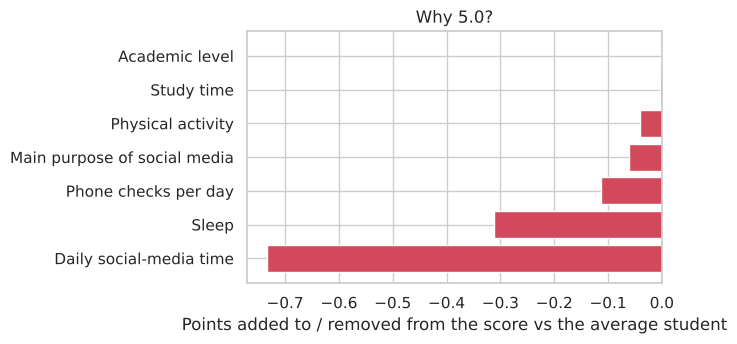

Student 2 (mixed habits) 


SCORE 6.1/10  (typical range 5.5-6.8)  ->  Moderate
Your habits are mixed. A few small, steady changes could make a real difference. 

WHAT PUSHED THE SCORE:
 - Daily social-media time (5 h/day) lowered your score by about 0.08 points compared with the average student.
 - Phone checks per day (170 times/day) lowered your score by about 0.06 points compared with the average student.
 - Sleep (6.6 h/night) had almost no effect.
 - Academic level (Undergraduate) had almost no effect.

ADVICE:
 * Sleep (model estimate ~+0.57 if improved): You sleep about 6.6 hours a night. Most adults feel best with 7-9 hours. Try going to bed 15-20 minutes earlier every few days, keep the same wake-up time, and keep your phone out of reach for the last 30 minutes before sleep.
 * Daily social-media time (lowered your score by ~0.08): You spend about 5.0 hours a day on social media. There is no magic number, but cutting back gradually (30-60 minutes) works better than quitting suddenly. Use app timers, and

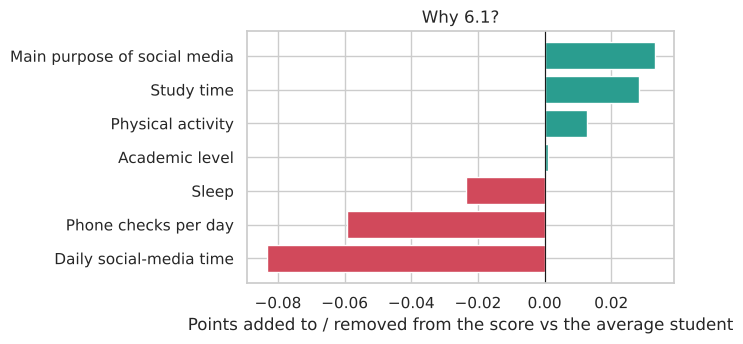

Student 3 (balanced routine) 


SCORE 8.1/10  (typical range 7.4-8.7)  ->  Good
Your habits look healthy overall. Focus on keeping what works and fine-tuning one or two things. 

WHAT PUSHED THE SCORE:
 - Physical activity (2.5 h/day) had almost no effect.
 - Academic level (Graduate) had almost no effect.
 - Study time (5 h/day) raised your score by about 0.05 points compared with the average student.
 - Main purpose of social media (Education) raised your score by about 0.06 points compared with the average student.

ADVICE:
 * No habit needs changing right now.

STRENGTHS:
 + Daily social-media time: working in your favour (+1.00). Keep it up.
 + Sleep: working in your favour (+0.39). Keep it up.
 + Phone checks per day: working in your favour (+0.36). Keep it up.

PLAN TARGETS (4 weeks):

VIDEOS:
 - How to make stress your friend (Kelly McGonigal (TED)) https://www.youtube.com/watch?v=RcGyVTAoXEU
COURSES:
 - The Science of Well-Being [Coursera] https://www.coursera.org/learn/the-science-of-well-being
 - The Scien

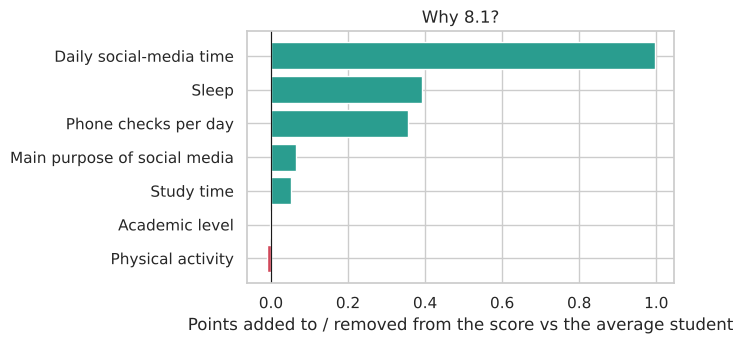

In [23]:
def plot_drivers(res):
    d = res["drivers"].sort_values("contribution")
    plt.figure(figsize=(7, 3.6))
    plt.barh(d["label"], d["contribution"], color=["#D1495B" if c < 0 else "#2A9D8F" for c in d["contribution"]])
    plt.axvline(0, color="k", lw=0.8); plt.xlabel("Points added to / removed from the score vs the average student")
    plt.title(f"Why {res['score']:.1f}?"); plt.tight_layout(); plt.show()

def show_result(res):
    lo, hi = res["range"]
    print(f"SCORE {res['score']:.1f}/10  (typical range {lo:.1f}-{hi:.1f})  ->  {res['band']}")
    print(res["band_message"], "\n")
    print("WHAT PUSHED THE SCORE:"); [print(" -", t) for t in res["driver_text"][:4]]
    print("\nADVICE:")
    for a in res["advice"]:
        why = (f"lowered your score by ~{abs(a['contribution']):.2f}" if a["contribution"] <= -0.05
               else f"model estimate ~{a['gain']:+.2f} if improved")
        print(f" * {a['label']} ({why}): {a['text']}")
    if not res["advice"]: print(" * No habit needs changing right now.")
    print("\nSTRENGTHS:"); [print(" +", s) for s in res["strengths"]]
    print("\nPLAN TARGETS (4 weeks):")
    for c in [c for c in res["changes"] if c["feature"] in STEPS][:3]:
        print(f" - {c['label']}: {c['current']:.1f} -> {c['target']:.1f}")
    if res["plan_gain"] >= 0.1:
        print(f"   Model estimate if all targets are reached together: {res['plan_gain']:+.2f} points")
    print("\nVIDEOS:"); [print(f" - {r.title} ({r.creator}) {r.url}") for r in res["videos"].itertuples()]
    print("COURSES:"); [print(f" - {r.title} [{r.platform}] {r.url}") for r in res["courses"].itertuples()]
    if res["show_support"]: print("\nSUPPORT:", SUPPORT_NOTE)

examples = {
 "Student 1 (late nights, heavy phone use)": dict(Avg_Daily_Usage_Hours=7.5, Daily_Unlocks=240, Study_Hours=1.0,
        Physical_Activity_Hours=0.9, Sleep_Hours_Per_Night=5.0, Academic_Level="Undergraduate", Purpose_Of_Use="Entertainment"),
 "Student 2 (mixed habits)": dict(Avg_Daily_Usage_Hours=5.0, Daily_Unlocks=170, Study_Hours=3.0,
        Physical_Activity_Hours=1.7, Sleep_Hours_Per_Night=6.6, Academic_Level="Undergraduate", Purpose_Of_Use="Networking"),
 "Student 3 (balanced routine)": dict(Avg_Daily_Usage_Hours=2.5, Daily_Unlocks=100, Study_Hours=5.0,
        Physical_Activity_Hours=2.5, Sleep_Hours_Per_Night=8.0, Academic_Level="Graduate", Purpose_Of_Use="Education"),
}
for title, inputs in examples.items():
    print("=" * 90, "\n" + title, "\n" + "=" * 90)
    res = assess(artifact, inputs, resources)
    show_result(res); plot_drivers(res)

**The 4-week plan for Student 1** (the dashboard also offers this as a download):

In [24]:
res1 = assess(artifact, examples["Student 1 (late nights, heavy phone use)"], resources)
display(res1["ramp"]); display(res1["schedule"])

,Week,Habit,Target,How
0,1,Daily social-media time,7.2 h/day,Set an app timer; keep the last hour before be...
1,1,Sleep,5.2 h/night,Fixed wake-up time; bedtime a little earlier; ...
2,1,Phone checks per day,230 checks/day,Notifications off; check messages in batches.
3,2,Daily social-media time,7.0 h/day,Set an app timer; keep the last hour before be...
4,2,Sleep,5.5 h/night,Fixed wake-up time; bedtime a little earlier; ...
5,2,Phone checks per day,220 checks/day,Notifications off; check messages in batches.
6,3,Daily social-media time,6.8 h/day,Set an app timer; keep the last hour before be...
7,3,Sleep,5.8 h/night,Fixed wake-up time; bedtime a little earlier; ...
8,3,Phone checks per day,210 checks/day,Notifications off; check messages in batches.
9,4,Daily social-media time,6.5 h/day,Set an app timer; keep the last hour before be...


,Day,Plan
0,Mon,Daily social-media time: aim for 7.2 h/day | S...
1,Tue,Daily social-media time: aim for 7.2 h/day | S...
2,Wed,Daily social-media time: aim for 7.2 h/day | S...
3,Thu,Daily social-media time: aim for 7.2 h/day | S...
4,Fri,Daily social-media time: aim for 7.2 h/day | S...
5,Sat,Daily social-media time: aim for 7.2 h/day | S...
6,Sun,Daily social-media time: aim for 7.2 h/day | S...


## 15. Testing the complete system
Before trusting the system we test it. Each `assert` stops the notebook with an error if something is wrong, so "all tests passed" really means something.

In [25]:
rng = np.random.default_rng(0)
def random_student():
    return {f: float(rng.uniform(*VALID_RANGES[f])) for f in NUMERIC_FEATURES} | {
        "Academic_Level": rng.choice(CHOICES["Academic_Level"]), "Purpose_Of_Use": rng.choice(CHOICES["Purpose_Of_Use"])}

# 1. Bands change exactly at the cut-offs
assert [score_to_band(s) for s in (4.99, 5.0, 6.99, 7.0)] == ["Needs attention", "Moderate", "Moderate", "Good"]

# 2. Bad inputs are rejected / adjusted
try:
    validate_inputs({**random_student(), "Academic_Level": "Professor"}); raise SystemExit("bad category accepted")
except ValueError: pass
row, warns = validate_inputs({**random_student(), "Sleep_Hours_Per_Night": 25}); assert row["Sleep_Hours_Per_Night"] == 10.0 and warns

# 3. 60 random students: valid score, SHAP adds up, plan moves habits the healthy way, resources always found
HEALTHY_DIRECTION = {"Sleep_Hours_Per_Night": 1, "Physical_Activity_Hours": 1, "Study_Hours": 1,
                     "Avg_Daily_Usage_Hours": -1, "Daily_Unlocks": -1}
for _ in range(60):
    s = random_student(); res = assess(artifact, s, resources)
    assert 0 <= res["score"] <= 10 and res["band"] in BAND_NAMES
    raw_pred = artifact["pipeline"].predict(pd.DataFrame([res["row"]])[FEATURES])[0]
    assert abs(res["base_value"] + res["drivers"]["contribution"].sum() - raw_pred) < 1e-6, "SHAP is not additive"
    assert res["range"][0] <= res["score"] <= res["range"][1]
    assert len(res["videos"]) > 0 and len(res["courses"]) > 0
    for c in res["changes"]:
        if c["feature"] in HEALTHY_DIRECTION:       # every target moves the habit in the healthy direction, inside valid range
            assert (c["target"] - c["current"]) * HEALTHY_DIRECTION[c["feature"]] > 0
            assert VALID_RANGES[c["feature"]][0] <= c["target"] <= VALID_RANGES[c["feature"]][1]
    assert len(res["ramp"]) == 4 * len([c for c in res["changes"] if c["feature"] in STEPS][:3])

# 4. Common-sense check: more sleep should, on average, not lower the predicted score
more = [predict_score(artifact, {**s, "Sleep_Hours_Per_Night": min(s["Sleep_Hours_Per_Night"] + 1, 10)}) - predict_score(artifact, s)
        for s in (random_student() for _ in range(100))]
assert np.mean(more) > 0, "more sleep lowers the score on average?"
print(f"Average effect of +1 h sleep: {np.mean(more):+.2f} points")

# 5. The saved file reloads and gives identical predictions
reloaded = joblib.load("Mental_Health_Model.pkl")
s = random_student(); assert predict_score(reloaded, s) == predict_score(artifact, s)

# 6. All resource links look valid
assert resources["url"].str.startswith("https://").all()
print("ALL TESTS PASSED")

Average effect of +1 h sleep: +0.10 points
ALL TESTS PASSED


## 16. Export the dashboard files
These cells write `mh_engine.py` (the same code as section 13) and `requirements.txt`. Then run in a terminal:
```
pip install -r requirements.txt
streamlit run app.py
```
Use the same scikit-learn version for training and for the dashboard (the model file records the version it was trained with, and the dashboard warns if it differs).

In [26]:
%%writefile mh_engine.py
"""
mh_engine.py - the "brain" of the Mental Health Assessment & Recommendation System.

EDUCATIONAL PROJECT. This is NOT a medical or diagnostic tool.

What it does, step by step:
  1. validate the user's inputs
  2. predict a wellbeing score (0-10) with the trained ML pipeline
  3. explain the prediction with SHAP (which habits pushed the score up or down)
  4. turn the explanation into written advice (rule-based, easy to defend)
  5. run "what-if" tests with the model (e.g. what if I sleep 30 min more?)
  6. build a 4-week improvement plan and a weekly schedule
  7. match videos and courses from a curated CSV
"""
import numpy as np
import pandas as pd

# ##### SECTION 1: constants #####
NUMERIC_FEATURES = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
]
CATEGORICAL_FEATURES = ["Academic_Level", "Purpose_Of_Use"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "Mental_Health_Score"

CHOICES = {
    "Academic_Level": ["High School", "Undergraduate", "Graduate"],
    "Purpose_Of_Use": ["Education", "Entertainment", "Networking", "News"],
}
# Allowed input ranges = (a little wider than) the range seen in the training data
VALID_RANGES = {
    "Avg_Daily_Usage_Hours": (1.0, 9.0),
    "Daily_Unlocks": (60, 280),
    "Study_Hours": (0.3, 8.5),
    "Physical_Activity_Hours": (0.0, 4.2),
    "Sleep_Hours_Per_Night": (3.5, 10.0),
}
FRIENDLY = {
    "Avg_Daily_Usage_Hours": "Daily social-media time",
    "Daily_Unlocks": "Phone checks per day",
    "Study_Hours": "Study time",
    "Physical_Activity_Hours": "Physical activity",
    "Sleep_Hours_Per_Night": "Sleep",
    "Academic_Level": "Academic level",
    "Purpose_Of_Use": "Main purpose of social media",
}
UNITS = {
    "Avg_Daily_Usage_Hours": "h/day", "Daily_Unlocks": "times/day",
    "Study_Hours": "h/day", "Physical_Activity_Hours": "h/day",
    "Sleep_Hours_Per_Night": "h/night",
}
# Score bands (design choice: cut-offs at 5 and 7 give roughly 17% / 51% / 32% of students)
BAND_EDGES = (5.0, 7.0)
BAND_NAMES = ("Needs attention", "Moderate", "Good")

DISCLAIMER = (
    "Educational project - not a medical or psychological diagnosis. The score comes from a "
    "machine-learning model trained on a public student-survey dataset and has not been "
    "clinically validated. Your answers are used only to compute this result and are not saved."
)
SUPPORT_NOTE = (
    "If you have felt low for a long time, or have thoughts of harming yourself, please talk to "
    "someone you trust, a doctor, or a counsellor. In Pakistan you can call the Umang helpline on "
    "0311-7786264 (listed as 24/7 - check umang.com.pk for current details). If you are in "
    "immediate danger, contact your local emergency services."
)


# ##### SECTION 2: validation and bands #####
def score_to_band(score):
    """Turn a 0-10 score into a band name."""
    if score < BAND_EDGES[0]:
        return BAND_NAMES[0]
    if score < BAND_EDGES[1]:
        return BAND_NAMES[1]
    return BAND_NAMES[2]


def validate_inputs(raw):
    """Check the user's inputs. Returns (clean_row, warnings). Raises ValueError if unusable."""
    row, warnings = {}, []
    for f in NUMERIC_FEATURES:
        if f not in raw or raw[f] is None or pd.isna(raw[f]):
            raise ValueError(f"Missing value for {FRIENDLY[f]}")
        value = float(raw[f])
        lo, hi = VALID_RANGES[f]
        if value < lo or value > hi:
            warnings.append(f"{FRIENDLY[f]} = {value:g} is outside the range the model "
                            f"was trained on ({lo:g}-{hi:g}); it was adjusted to fit.")
            value = min(max(value, lo), hi)
        row[f] = value
    for f in CATEGORICAL_FEATURES:
        if raw.get(f) not in CHOICES[f]:
            raise ValueError(f"{FRIENDLY[f]} must be one of {CHOICES[f]}")
        row[f] = raw[f]
    return row, warnings


# ##### SECTION 3: prediction and SHAP explanation #####
def predict_score(artifact, row):
    """Predicted wellbeing score (0-10) for one student."""
    X = pd.DataFrame([row])[FEATURES]
    return float(np.clip(artifact["pipeline"].predict(X)[0], 0, 10))


_EXPLAINERS = {}


def explain_prediction(artifact, row):
    """
    SHAP explanation for one student.
    SHAP gives every column of the encoded data a contribution; we add the one-hot columns back
    together so each ORIGINAL feature gets one number: how many score points it added (+) or
    removed (-) compared with the average student.
    Returns (table, base_value).
    """
    import shap  # imported here so the rest of the module works without SHAP installed
    pipe = artifact["pipeline"]
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    if id(model) not in _EXPLAINERS:
        _EXPLAINERS[id(model)] = shap.TreeExplainer(model)
    explainer = _EXPLAINERS[id(model)]

    Xt = prep.transform(pd.DataFrame([row])[FEATURES])
    values = np.asarray(explainer.shap_values(Xt))[0]
    base = float(np.ravel(explainer.expected_value)[0])

    contrib = {f: 0.0 for f in FEATURES}
    for name, v in zip(prep.get_feature_names_out(), values):
        short = name.split("__", 1)[1]
        for f in FEATURES:
            if short == f or short.startswith(f + "_"):
                contrib[f] += float(v)
                break
    table = pd.DataFrame({
        "feature": FEATURES,
        "label": [FRIENDLY[f] for f in FEATURES],
        "value": [row[f] for f in FEATURES],
        "contribution": [contrib[f] for f in FEATURES],
    }).sort_values("contribution").reset_index(drop=True)
    return table, base


def describe_driver(r):
    """One plain-English sentence for one row of the SHAP table."""
    f, c = r["feature"], r["contribution"]
    value = f"{r['value']:g} {UNITS[f]}" if f in UNITS else str(r["value"])
    if abs(c) < 0.05:
        return f"{r['label']} ({value}) had almost no effect."
    direction = "raised" if c > 0 else "lowered"
    return f"{r['label']} ({value}) {direction} your score by about {abs(c):.2f} points compared with the average student."


# ##### SECTION 4: written advice (rule-based) #####
def advice_for(feature, row):
    """Short, practical advice text for one habit. Written for a student audience."""
    v = row.get(feature)
    if feature == "Sleep_Hours_Per_Night":
        if v < 7:
            return (f"You sleep about {v:.1f} hours a night. Most adults feel best with 7-9 hours. Try going "
                    "to bed 15-20 minutes earlier every few days, keep the same wake-up time, and keep your "
                    "phone out of reach for the last 30 minutes before sleep.")
        return (f"Your sleep ({v:.1f} h) is in a healthy range. Protect it by keeping a regular bedtime - "
                "irregular timing can hurt as much as too few hours.")
    if feature == "Physical_Activity_Hours":
        return (f"You get about {v * 60:.0f} minutes of physical activity a day. Adults are generally advised to "
                "aim for at least 150 minutes of moderate activity a week (roughly 20-30 minutes a day). Start "
                "with a 15-minute walk after class or after a meal and add 5 minutes each week.")
    if feature == "Avg_Daily_Usage_Hours":
        return (f"You spend about {v:.1f} hours a day on social media. There is no magic number, but cutting "
                "back gradually (30-60 minutes) works better than quitting suddenly. Use app timers, and make "
                "the last hour before bed phone-free.")
    if feature == "Daily_Unlocks":
        return (f"You pick up your phone about {v:.0f} times a day. Turn off non-essential notifications, move "
                "distracting apps off your home screen, and check messages in batches (for example once an hour).")
    if feature == "Study_Hours":
        return (f"You study about {v:.1f} hours a day. In this dataset, students with a steady study routine "
                "scored higher. Try two or three focused 45-minute blocks with 10-minute breaks, at the same "
                "times each day. (Study time and screen time are linked in the data, so treat this as a pattern, "
                "not a rule.)")
    if feature == "Purpose_Of_Use":
        return ("Most of your social-media time is for entertainment. Moving part of it to learning or real "
                "connection (messaging a friend, a study group, a skill video) can make the time feel more worthwhile.")
    return ""


# ##### SECTION 5: what-if simulation and suggested changes #####
# Rule-based targets: (step, limit) = add/subtract 'step' over 4 weeks but never go past 'limit'
STEPS = {
    "Sleep_Hours_Per_Night": (+1.0, 8.0),
    "Physical_Activity_Hours": (+0.3, 2.0),
    "Avg_Daily_Usage_Hours": (-1.0, 2.5),
    "Daily_Unlocks": (-40, 100),
    "Study_Hours": (+0.5, 4.0),
}


def what_if(artifact, row, changes):
    """Predicted score if the habits in `changes` (dict feature -> new value) were different."""
    return predict_score(artifact, {**row, **changes})


def suggest_changes(artifact, row, drivers=None, min_gain=0.10):
    """
    Choose which habits to work on, and by how much.
      * the TARGET comes from a simple rule (STEPS) - easy to explain and safe;
      * a habit is chosen if it lowers this student's score (SHAP) or if the model estimates a clear gain;
      * the model's estimate is shown as 'gain' (a pattern in the data, not a guaranteed effect).
    Single-habit estimates from tree models are noisy (typical error is about 0.4 points), so small
    gains are kept but not advertised. Returns a list, most important first.
    """
    current = predict_score(artifact, row)
    hurt = {} if drivers is None else {f: -c for f, c in zip(drivers["feature"], drivers["contribution"])}
    out = []
    for f, (step, limit) in STEPS.items():
        cur = row[f]
        if (step > 0 and cur >= limit) or (step < 0 and cur <= limit):
            continue                                              # already at a healthy level
        new = min(cur + step, limit) if step > 0 else max(cur + step, limit)
        gain = what_if(artifact, row, {f: new}) - current
        if hurt.get(f, 0.0) >= 0.05 or gain >= min_gain:
            out.append({"feature": f, "label": FRIENDLY[f], "current": cur, "target": new,
                        "gain": gain, "hurt": hurt.get(f, 0.0)})
    if row["Purpose_Of_Use"] == "Entertainment":
        gain = what_if(artifact, row, {"Purpose_Of_Use": "Education"}) - current
        if hurt.get("Purpose_Of_Use", 0.0) >= 0.05 or gain >= min_gain:
            out.append({"feature": "Purpose_Of_Use", "label": FRIENDLY["Purpose_Of_Use"], "current": "Entertainment",
                        "target": "Education", "gain": gain, "hurt": hurt.get("Purpose_Of_Use", 0.0)})
    return sorted(out, key=lambda d: -(max(d["hurt"], 0) + max(d["gain"], 0)))


def combined_effect(artifact, row, changes, n_habits=3):
    """Model estimate if the top numeric habits all reach their targets together (more stable than one at a time)."""
    chosen = [c for c in changes if c["feature"] in STEPS][:n_habits]
    if not chosen:
        return 0.0
    return what_if(artifact, row, {c["feature"]: c["target"] for c in chosen}) - predict_score(artifact, row)


# ##### SECTION 6: improvement plan #####
HOW = {
    "Sleep_Hours_Per_Night": "Fixed wake-up time; bedtime a little earlier; no phone in bed.",
    "Physical_Activity_Hours": "Walk, stretch, sport or cycling - pick something you enjoy.",
    "Avg_Daily_Usage_Hours": "Set an app timer; keep the last hour before bed phone-free.",
    "Daily_Unlocks": "Notifications off; check messages in batches.",
    "Study_Hours": "Focused 45-minute blocks at fixed times, 10-minute breaks.",
}


def _fmt(feature, value):
    if feature == "Physical_Activity_Hours":
        return f"{value * 60:.0f} min/day"
    if feature == "Daily_Unlocks":
        return f"{value:.0f} checks/day"
    return f"{value:.1f} {UNITS[feature]}"


def build_weekly_plan(changes, n_habits=3):
    """
    4-week ramp (25% -> 50% -> 75% -> 100% of the change) plus a Mon-Sun schedule
    for week 1. Uses only numeric habits. Small steps are easier to keep.
    Returns (ramp_table, schedule_table).
    """
    chosen = [c for c in changes if c["feature"] in STEPS][:n_habits]
    ramp_rows = []
    for week, share in enumerate([0.25, 0.5, 0.75, 1.0], start=1):
        for c in chosen:
            value = c["current"] + (c["target"] - c["current"]) * share
            ramp_rows.append({"Week": week, "Habit": c["label"], "Target": _fmt(c["feature"], value),
                              "How": HOW[c["feature"]]})
    ramp = pd.DataFrame(ramp_rows)

    days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    schedule = []
    for d in days:
        tasks = []
        for c in chosen:
            f = c["feature"]
            w1 = c["current"] + (c["target"] - c["current"]) * 0.25
            if f in ("Sleep_Hours_Per_Night", "Avg_Daily_Usage_Hours", "Daily_Unlocks"):
                tasks.append(f"{c['label']}: aim for {_fmt(f, w1)}")
            elif f == "Physical_Activity_Hours" and d in ("Mon", "Wed", "Fri", "Sat"):
                tasks.append(f"Move for {_fmt(f, w1)}")
            elif f == "Study_Hours" and d not in ("Sat", "Sun"):
                tasks.append(f"Study {_fmt(f, w1)} in focused blocks")
        if d == "Sun":
            tasks.append("Weekly check-in: what helped? Re-run this assessment and compare.")
        schedule.append({"Day": d, "Plan": " | ".join(tasks) if tasks else "Rest day"})
    return ramp, pd.DataFrame(schedule)


def plan_to_text(ramp, schedule):
    """Plain-text version of the plan (for the download button)."""
    lines = ["MY 4-WEEK IMPROVEMENT PLAN (educational, not medical advice)", ""]
    for week, grp in ramp.groupby("Week"):
        lines.append(f"Week {week}")
        lines += [f"  - {r.Habit}: {r.Target}  ({r.How})" for r in grp.itertuples()]
        lines.append("")
    lines.append("WEEK-1 SCHEDULE")
    lines += [f"  {r.Day}: {r.Plan}" for r in schedule.itertuples()]
    return "\n".join(lines)


# ##### SECTION 7: video and course matching #####
# Which resource tags go with which habit
FACTOR_TAGS = {
    "Sleep_Hours_Per_Night": ["sleep"],
    "Physical_Activity_Hours": ["activity"],
    "Avg_Daily_Usage_Hours": ["screen_time"],
    "Daily_Unlocks": ["screen_time"],
    "Study_Hours": ["study", "habits"],
    "Purpose_Of_Use": ["screen_time"],
}


def recommend_resources(resources, problem_features, k_videos=3, k_courses=3):
    """
    Pick videos / courses whose tags match the habits that hurt the score most.
    `resources` is the curated CSV (columns: type, title, creator, platform, url, tags, why).
    Items tagged 'general' always get a small bonus so the list is never empty.
    """
    wanted = []
    for f in problem_features:
        wanted += FACTOR_TAGS.get(f, [])
    res = resources.copy()

    def score(tag_string):
        tags = [t.strip() for t in str(tag_string).split(";")]
        return sum(1.0 for t in tags if t in wanted) + (0.25 if "general" in tags else 0)

    res["match"] = res["tags"].apply(score) + res["type"].isin(["video", "course"]) * 0.1   # prefer exact links
    res = res.sort_values("match", ascending=False, kind="stable")
    videos = res[(res["type"].isin(["video", "video_search"])) & (res["match"] > 0.15)].head(k_videos)
    courses = res[(res["type"].isin(["course", "course_search"])) & (res["match"] > 0.15)].head(k_courses)
    return videos.reset_index(drop=True), courses.reset_index(drop=True)


# ##### SECTION 8: the full assessment #####
BAND_MESSAGE = {
    "Good": "Your habits look healthy overall. Focus on keeping what works and fine-tuning one or two things.",
    "Moderate": "Your habits are mixed. A few small, steady changes could make a real difference.",
    "Needs attention": ("Several of your habits are pulling your score down. That is common and changeable - "
                        "start with one small change below, and consider talking to someone you trust."),
}


def assess(artifact, raw_inputs, resources=None):
    """Run the whole pipeline for one student and return everything the dashboard needs."""
    row, warnings = validate_inputs(raw_inputs)
    score = predict_score(artifact, row)
    band = score_to_band(score)
    q10, q90 = artifact["residual_q10"], artifact["residual_q90"]
    drivers, base = explain_prediction(artifact, row)

    actionable = drivers[drivers["feature"].isin(FACTOR_TAGS)]
    helping = actionable[actionable["contribution"] >= 0.15].sort_values("contribution", ascending=False)
    strengths = [f"{r.label}: working in your favour (+{r.contribution:.2f}). Keep it up."
                 for r in helping.itertuples()]

    changes = suggest_changes(artifact, row, drivers)
    advice = [{"label": c["label"], "feature": c["feature"], "contribution": -c["hurt"], "gain": c["gain"],
               "text": advice_for(c["feature"], row)} for c in changes[:4]]
    plan_gain = combined_effect(artifact, row, changes)
    ramp, schedule = build_weekly_plan(changes)

    result = {
        "row": row, "warnings": warnings, "score": score, "band": band,
        "range": (float(np.clip(score + q10, 0, 10)), float(np.clip(score + q90, 0, 10))),
        "band_message": BAND_MESSAGE[band], "base_value": base, "drivers": drivers,
        "driver_text": [describe_driver(r) for _, r in drivers.iterrows()],
        "advice": advice, "strengths": strengths, "changes": changes, "plan_gain": plan_gain,
        "ramp": ramp, "schedule": schedule, "show_support": band == "Needs attention",
    }
    if resources is not None:
        focus = [c["feature"] for c in changes[:3]]
        result["videos"], result["courses"] = recommend_resources(resources, focus)
    return result

Overwriting mh_engine.py


In [27]:
Path("requirements.txt").write_text(
    "numpy>=1.26\npandas>=2.0\n"
    f"scikit-learn=={sklearn.__version__}\n"      # same version that trained the model
    "shap>=0.45\nmatplotlib>=3.7\njoblib>=1.3\nstreamlit>=1.50\n")
print(Path("requirements.txt").read_text())

numpy>=1.26
pandas>=2.0
scikit-learn==1.9.1
shap>=0.45
matplotlib>=3.7
joblib>=1.3
streamlit>=1.50



## 17. Viva cheat-sheet (read this the night before)

**Q: What problem do you solve?** A: Predict a 0-10 wellbeing score from a student's daily habits, explain it, and turn the explanation into practical advice. It is educational, not diagnostic.

**Q: Why regression, and why bands?** A: The target is a number, so regression. Bands (Needs attention < 5, Moderate 5-7, Good >= 7) make the result easier to read; the cut-offs are a design choice that gives roughly 17% / 51% / 32% of students.

**Q: How good is the model?** A: See sections 8-10: cross-validated and test R2 and MAE, compared with a baseline that always predicts the average (MAE about 1.1 vs about 0.4 for our model). The train score is higher than the test score - normal for a Random Forest - so we chose the model by cross-validation, not by training score.

**Q: Why not use country, gender, age or stress?** A: Section 7. Stress adds almost no accuracy (it summarises the other habits). Country adds accuracy but is not changeable, raises privacy and fairness concerns, and advice must not depend on who you are. We accepted a small accuracy loss for fairness and actionable advice.

**Q: How do you avoid data leakage?** A: Split first; all scaling/encoding inside a `Pipeline` fitted on training data only; feature experiments and tuning done on the training set; test set used once.

**Q: What is SHAP?** A: A method that fairly splits a prediction among the inputs (from game theory). It tells us how many points each input added or removed compared with the average student. Test: base value + contributions = prediction.

**Q: SHAP and what-if disagree - why?** A: They answer different questions. SHAP compares you with the *average student*; what-if compares you with *your own* changed habit. A student near the average has small SHAP values but can still gain from improving.

**Q: Are the recommendations medical advice?** A: No. They are rule-based tips using general public-health guidance. Targets come from simple rules; the model only estimates effects, and small single-habit estimates (under ~0.1 points) are noise. Low scores show a support note and the Umang helpline.

**Q: What are the limitations?** A: (1) The dataset looks simulated: very clean, and the score follows the habits closely, so real-world accuracy is unknown. (2) The score is not clinically validated. (3) Self-reported inputs. (4) Associations, not causes. (5) Tree models give jumpy what-if estimates for unusual profiles (we tried monotonic constraints: more consistent but 4 points of R2 lower).

**Q: What would you do next?** A: Collect real, consented survey data with a validated scale (for example PHQ-9 or WHO-5) with ethics approval, validate with psychologists, add the YouTube/Coursera APIs, and track users' progress over time.